# Matriz de Confusion y Metricas de Clasificacion en Scikit-Learn

1. ¿Que es la matriz de confusion?
2. Metricas de desempeño de un clasificador
3. Calculo de matriz de confusion y metricas de desempeño (clasificador binario)
4. calculo matriz de confusion y metricas de desempeño (clasificador multiclase)

### 1. ¿Que es la matriz de confusion?

La matriz de confusion es una manera de representar graficamente los aciertos y los errores cometidos por un clasificador para cada ua de las categorias de interes

![](../img/matrizconfusion.png)


#### 2. Métricas de desempeño de un clasificador

A partir de la matriz de confusión podemos calcular varias métricas de desempeño (cada una de las cuales resultará más o menos adecuada dependiendo del uso que le queramos dar al clasificador).

Antes de definir las métricas definamos los conceptos de verdaderos positivos (TP), falsos positivos (FP), verdaderos negativos (TN) y falsos negativos (FN).

- **Positivos y negativos**: la denominación que le daremos a cada categoría (en el caso de la clasificación binaria).
    - Por ejemplo: "cat_A" $\rightarrow$ "negativo", "cat_B" $\rightarrow$ "positivo

- **Verdaderos positivos (TP)**: la cantidad de datos que siendo positivos fueron detectados correctamente como positivos.
    - En la matriz anterior: cantidad de datos categoría B que fueron detectados correctamente como categoría B = 8

- **Falsos positivos (FP)**: la cantidad de datos que siendo negativos fueron detectados **incorrectamente** como positivos.
    - En la matriz anterior: cantidad de datos categoría A que fueron detectados **incorrectamente** como categoría B = 2

- **Verdaderos negativos (TN)**: la cantidad de datos que siendo negativos fueron detectados correctamente como negativos.
    - En la matriz anterior: cantidad de datos categoría A que fueron detectados correctamente como categoría A = 89

- **Falsos negativos (FN)**: la cantidad de datos que siendo positivos fueron detectados **incorrectamente** como negativos.
    - En la matriz anterior: cantidad de datos categoría A que fueron detectados correctamente como categoría A = 1


#### 2.1. La exactitud

- Es simplemente la relación entre el número de aciertos (datos clasificados correctamente) sobre el número total de datos

$$ \text{exactitud} = \frac{\text{Número de aciertos}}{\text{Número total de datos}}$$

- En el caso anterior:
    - Número de aciertos: 89+8 = 97
    - Número total de datos: 89+8+2+1 = 100
    - Exactitud: 97/100 (o 97%)

- Limitaciones de la exactitud: puede "enmascarar" el desempeño del clasificador para una categoría en particular

#### 2.2. Precision

- Es la proporción de datos clasificados como positivos que realmente son positivos:

$$\text{precision} = \frac{TP}{TP+FP}$$

  - En la matriz anterior:

  $$\text{precision} = \frac{8}{8+2} = \frac{8}{10} = 0.80$$

#### 2.3. Recall

- Es la proporción de datos positivos que fueron detectados correctamente como positivos:

$$\text{recall} = \frac{TP}{TP+FN}$$

  - En la matriz anterior:

  $$\text{recall} = \frac{8}{8+1} = \frac{8}{9} = 0.89$$

#### 2.4. F1-score

- Es la media armónica del precision y el recall:

$$\text{F1-score} = 2 \cdot \frac{\text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$$

  - En la matriz anterior:

  $$\text{F1-score} = 2 \cdot \frac{0.80 \cdot 0.89}{0.80 + 0.89} = 0.84$$

### 3. Calculo de matriz de confusion y metricas de desempeño (clasificador binario)

supongamos que construimos un clasificador binario para estas categorias:

- 0: negativo
- 1: positivo

In [3]:
from sklearn.metrics import confusion_matrix

# Definir categorias reales y predichas
y_true = [0, 1, 1, 1, 0, 1, 0, 1, 0]
y_pred = [0, 1, 1, 1, 1, 1, 0, 1, 0]

# Calcular matriz de confusión
cm = confusion_matrix(y_true, y_pred)
print(cm)


[[3 1]
 [0 5]]


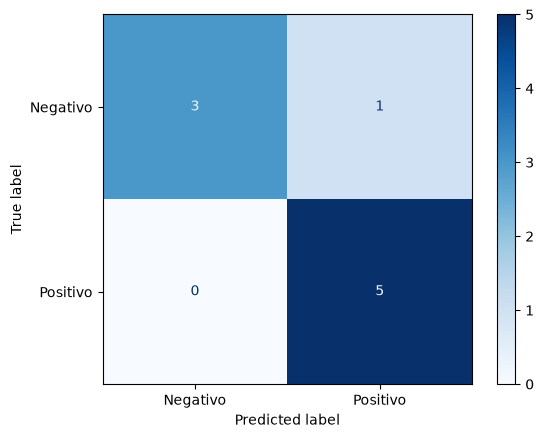

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Mostrar la matriz gráficamente
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negativo", "Positivo"])
disp.plot(cmap=plt.cm.Blues)
plt.show()


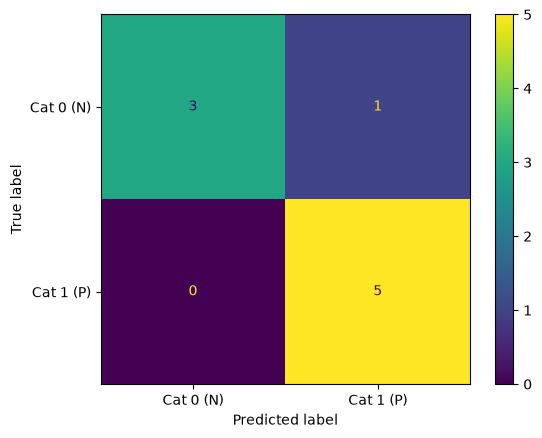

In [5]:
labels = ['Cat 0 (N)', 'Cat 1 (P)']
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=labels)

- TP -> 5
- TN -> 3
- FP -> 1
- FN -> 0

In [10]:
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
print('TP', tp)
print('FN', fn)
print('TN', tn)
print('FP', fp)

TP 5
FN 0
TN 3
FP 1


In [11]:
# calcular exactitud, presicion, recall, f1-score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print('Exactitud: ', accuracy_score(y_true, y_pred))
print('Presicion: ', precision_score(y_true, y_pred))
print('Recall: ', recall_score(y_true, y_pred))
print('f1-score: ', f1_score(y_true, y_pred))

Exactitud:  0.8888888888888888
Presicion:  0.8333333333333334
Recall:  1.0
f1-score:  0.9090909090909091


In [12]:
# generar reporte clasificador
from sklearn.metrics import  classification_report

print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.75      0.86         4
           1       0.83      1.00      0.91         5

    accuracy                           0.89         9
   macro avg       0.92      0.88      0.88         9
weighted avg       0.91      0.89      0.89         9

